In [77]:
#Importing libraries needed
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [78]:
#Loading the dataset
df = pd.read_csv("creditcard.csv")

In [79]:
#Checking if the dataset was loaded successfully
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [80]:
#Checking if there are any empty cells
df.isna().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [81]:
#Dropping the column Time, because we do not need it for checking any information for fraud
df.drop(labels = 'Time', axis = 1, inplace = True)

In [82]:
#Checking if column was removed successfully
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'],
      dtype='object')

In [83]:
#Setting target data for training and testing
target = df.Class

In [84]:
#Checking if target data was loaded successfully
target

0         0
1         0
2         0
3         0
4         0
         ..
284802    0
284803    0
284804    0
284805    0
284806    0
Name: Class, Length: 284807, dtype: int64

In [85]:
#Removing the target: Class, column from the dataframe
df.drop(labels = 'Class', axis = 1, inplace = True)

In [86]:
#Checking if column was removed successfully
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'],
      dtype='object')

In [87]:
#Splitting between training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(df, target, test_size = 0.15, stratify = target, random_state = 1)

In [88]:
#Checking if the splitting process was successful
X_train, X_test, y_train, y_test

(              V1        V2        V3        V4        V5        V6        V7  \
 101748 -0.737662  0.877699  2.238997  0.080510 -0.218879 -0.599034  0.415185   
 90740   1.004793 -0.672297 -0.445963  0.667430  1.533548  4.418254 -0.925142   
 274597  1.776042 -1.071451 -0.285485  0.752185 -1.230161 -0.426358 -0.679677   
 31267   1.258513 -0.794463  1.057970 -0.738204 -1.396441 -0.054061 -1.208656   
 17616   1.354977 -0.734493  1.365681 -0.624978 -1.739542 -0.517413 -1.300679   
 ...          ...       ...       ...       ...       ...       ...       ...   
 249626 -0.312808  1.571520  0.625071  2.851596  1.440896  0.370273  1.559423   
 188363  2.313488 -1.066660 -2.698797 -1.810692  0.181929 -0.825158  0.014053   
 224660  1.980328  0.104427 -0.923277  1.353652  0.047918 -0.223057 -0.382536   
 206178  1.888991 -0.199603 -0.401767  1.366907 -0.105339  0.441041 -0.401390   
 99525   1.043656 -1.663870 -0.403771 -1.333184 -1.266211 -0.725187 -0.293248   
 
               V8        V

In [89]:
#Initializing StandardScaler and fitting it with the training samples
std = StandardScaler()
std.fit(X_train)

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [90]:
#Applying StandardScaler on the training and testing data
X_train_std = std.transform(X_train)
X_test_std = std.transform(X_test)

In [93]:
#Initializing LogisticRegression model and fitting
lrg = LogisticRegression(C = 1, random_state = 1, max_iter = 3000, solver = 'lbfgs')
lrg.fit(X_train_std, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multicla

In [94]:
#Testing the model accuracy
y_pred = lrg.predict(X_test_std)
print(f"Amount of wrong predictions: {(y_pred != y_test).sum()}")
print(f"Accuracy score is: {100 * accuracy_score(y_pred, y_test):.3f} %")

Amount of wrong predictions: 30
Accuracy score is: 99.930 %


In [95]:
'''The model achieved a vary high accuracy: near 100%. However, because the dataset is highly imbalanced, because there are mostly random transactions,
I focused on tuning the parameters to ensure there aren't any rare fraud cases missing. Despite testing various parameters, the model reached a stable 
performance ceiling, where it balances catching fraud without flagging many *innocent customers*.'''

"The model achieved a vary high accuracy: near 100%. However, because the dataset is highly imbalanced, because there are mostly random transactions,\nI focused on tuning the parameters to ensure there aren't any rare fraud cases missing. Despite testing various parameters, the model reached a stable \nperformance ceiling, where it balances catching fraud without flagging many *innocent customers*."

In [96]:
def plot_decision_regions(X, y, classifier, resolution = 0.02, xlabel = '', ylabel = ''):
    bg_colors = ('#A9CCE3', '#FAD7A0')
    point_colors = ('#2980B9', '#E67E22')
    cmap = ListedColormap(bg_colors)
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx1, xx2 = np.meshgrid(np.arange(x_min, x_max, resolution),np.arange(y_min, y_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.scatter(X[y == 0, 0], X[y == 0, 1], alpha = 0.2, c = point_colors[0],
                marker = 'o', label = 'Normal', edgecolor = 'white', linewidth = 0.3, s = 20)
    plt.scatter(X[y == 1, 0], X[y == 1, 1], alpha = 1.0, c = point_colors[1],
                marker = 'x', label = 'Fraud', s = 50, linewidths = 2)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(loc = 'upper right', frameon = True, facecolor = 'white')
    plt.grid(True, linestyle = '--', alpha = 0.2)

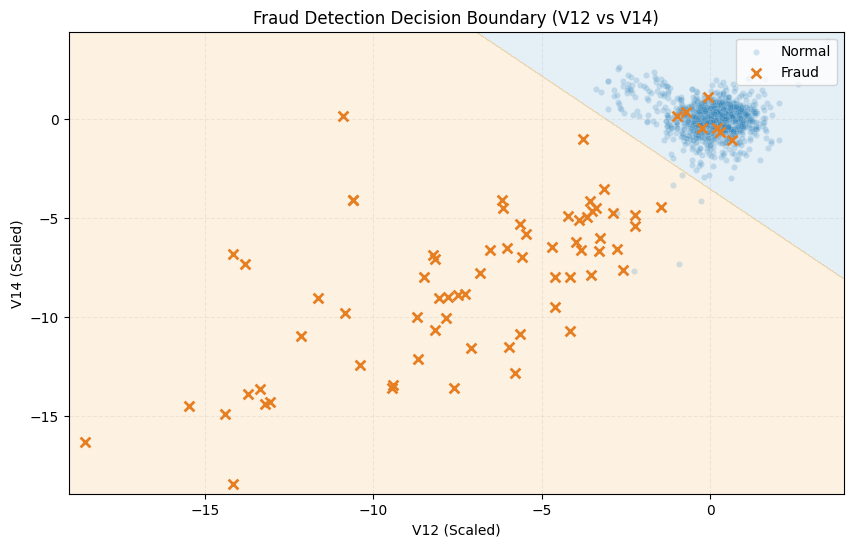

In [98]:
feat_idx = [11, 13] 
X_test_subset = X_test_std[:, feat_idx]
y_test_values = y_test.values
fraud_indices = np.where(y_test_values == 1)[0]
normal_indices = np.where(y_test_values == 0)[0][:1000] # Take only 1000 normal cases
plot_indices = np.concatenate([fraud_indices, normal_indices])
X_plot = X_test_subset[plot_indices]
y_plot = y_test_values[plot_indices]

lrg_vis = LogisticRegression(C = 1, class_weight = 'balanced')
lrg_vis.fit(X_plot, y_plot)

plt.figure(figsize=(10, 6))
plot_decision_regions(X_plot, y_plot, classifier = lrg_vis, xlabel = 'V12 (Scaled)', ylabel = 'V14 (Scaled)')
plt.title('Fraud Detection Decision Boundary (V12 vs V14)')
plt.show()